<a href="https://colab.research.google.com/github/bhagyoday-j/ML-Assignments/blob/main/TY-open-elective/Assingments/10_HR_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("arashnic/hr-analytics-job-change-of-data-scientists")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'hr-analytics-job-change-of-data-scientists' dataset.
Path to dataset files: /kaggle/input/hr-analytics-job-change-of-data-scientists


In [2]:
import os
import pandas as pd

# List files in the dataset directory
print(os.listdir(path))

['sample_submission.csv', 'aug_test.csv', 'aug_train.csv']


In [3]:
csv_path = os.path.join(path, "sample_submission.csv")
df = pd.read_csv(csv_path)

In [4]:
df.head()


,enrollee_id,target
0,32403,0.5
1,9858,0.5
2,31806,0.5
3,27385,0.5
4,27724,0.5


In [5]:

# Cell 1: Inspect the dataset structure

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset shape: (2129, 2)

Column names:
['enrollee_id', 'target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2129 entries, 0 to 2128
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   enrollee_id  2129 non-null   int64  
 1   target       2129 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 33.4 KB


In [6]:

# Cell 2: Inspect the available data

print("First 10 rows:")
display(df.head(10))

print("\nTarget value counts:")
print(df["target"].value_counts(dropna=False))

print("\nTarget summary:")
print(df["target"].describe())

print("\nDuplicate rows:", df.duplicated().sum())
print("Unique enrollee IDs:", df["enrollee_id"].nunique())


First 10 rows:


,enrollee_id,target
0,32403,0.5
1,9858,0.5
2,31806,0.5
3,27385,0.5
4,27724,0.5
5,217,0.5
6,21465,0.5
7,27302,0.5
8,12994,0.5
9,16287,0.5



Target value counts:
target
0.5    2129
Name: count, dtype: int64

Target summary:
count    2129.0
mean        0.5
std         0.0
min         0.5
25%         0.5
50%         0.5
75%         0.5
max         0.5
Name: target, dtype: float64

Duplicate rows: 0
Unique enrollee IDs: 2129


In [7]:

import os
import glob

print("Current directory:", os.getcwd())

print("\nCSV files available:")
for file in glob.glob("/content/**/*.csv", recursive=True):
    print(file)


Current directory: /content

CSV files available:
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_test.csv


In [10]:

import pandas as pd

url = "https://raw.githubusercontent.com/edyoda/data-science-complete-tutorial/master/Data/HR-Analytics/aug_train.csv"

try:
    df = pd.read_csv(url)
    print("Dataset downloaded successfully!")
    print("Shape:", df.shape)
    display(df.head())
except Exception as e:
    print("Download failed:", e)


Download failed: HTTP Error 404: Not Found


In [11]:

import pandas as pd

url = "https://raw.githubusercontent.com/Ben-Kanarick/Predicting-Job-Change/master/aug_train.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Shape: (19158, 14)

Columns:
['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job', 'training_hours', 'target']


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [12]:

# Cell 5: Understand the target and data quality

print("Target distribution:")
print(df["target"].value_counts(dropna=False))

print("\nTarget distribution in percentage:")
print((df["target"].value_counts(normalize=True, dropna=False) * 100).round(2))

print("\nMissing values by column:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nGender distribution:")
print(df["gender"].value_counts(dropna=False))

print("\nRace column available:", "race" in df.columns)


Target distribution:
target
0.0    14381
1.0     4777
Name: count, dtype: int64

Target distribution in percentage:
target
0.0    75.07
1.0    24.93
Name: proportion, dtype: float64

Missing values by column:
company_type              6140
company_size              5938
gender                    4508
major_discipline          2813
education_level            460
last_new_job               423
enrolled_university        386
experience                  65
enrollee_id                  0
city                         0
relevent_experience          0
city_development_index       0
training_hours               0
target                       0
dtype: int64

Gender distribution:
gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

Race column available: False


In [13]:

# Cell 6: Prepare a working copy and inspect feature values

data = df.copy()

# Remove the unique ID because it is not a meaningful predictive feature
data = data.drop(columns=["enrollee_id"])

print("Dataset shape after removing ID:", data.shape)

print("\nCategorical column values:")
categorical_cols = data.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(data[col].value_counts(dropna=False).head(10))

print("\nTarget data type:", data["target"].dtype)
print("Unique target values:", sorted(data["target"].unique()))


Dataset shape after removing ID: (19158, 13)

Categorical column values:

city:
city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
city_136     586
city_67      431
city_75      305
city_102     304
city_104     301
Name: count, dtype: int64

gender:
gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

relevent_experience:
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64

enrolled_university:
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
NaN                   386
Name: count, dtype: int64

education_level:
education_level
Graduate          11598
Masters            4361
High School        2017
NaN                 460
Phd                 414
Primary School      308
Name: count, dtype: int64

major_discipline:
major_discipline
STEM               14492
NaN                 2813
Humanities       

In [14]:

# Cell 7: Separate model features, target, and fairness audit data

from sklearn.model_selection import train_test_split

# Keep gender separately for fairness evaluation
gender_audit = df["gender"].copy()

# Target to predict
y = data["target"].astype(int)

# Exclude target and gender from model inputs for this baseline
X = data.drop(columns=["target", "gender"])

# Split all data together so the audit labels stay aligned
X_train, X_test, y_train, y_test, gender_train, gender_test = train_test_split(
    X,
    y,
    gender_audit,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

print("\nGender audit data aligned with test set:", len(gender_test) == len(y_test))
print("\nGender counts in test set:")
print(gender_test.value_counts(dropna=False))


Training features: (15326, 11)
Testing features: (3832, 11)

Training target distribution:
target
0    0.751
1    0.249
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.751
1    0.249
Name: proportion, dtype: float64

Gender audit data aligned with test set: True

Gender counts in test set:
gender
Male      2589
NaN        934
Female     276
Other       33
Name: count, dtype: int64


In [15]:

# Cell 8: Create preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns from training data
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully.")


Numerical features: ['city_development_index', 'training_hours']

Categorical features: ['city', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']

Preprocessing pipeline created successfully.


In [16]:

# Cell 9: Train the baseline classification model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train using training data only
model.fit(X_train, y_train)

print("Model training completed successfully!")

print("\nTraining accuracy:", round(model.score(X_train, y_train), 4))
print("Testing accuracy:", round(model.score(X_test, y_test), 4))


Model training completed successfully!

Training accuracy: 0.7814
Testing accuracy: 0.7758


In [17]:

# Cell 10: Evaluate the model on test data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Generate predictions
y_pred = model.predict(X_test)

# Calculate metrics
print("Classification Metrics")
print("-" * 35)
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Metrics
-----------------------------------
Accuracy : 0.7758
Precision: 0.587
Recall   : 0.3393
F1-score : 0.43

Confusion Matrix:
[[2649  228]
 [ 631  324]]

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.92      0.86      2877
           1       0.59      0.34      0.43       955

    accuracy                           0.78      3832
   macro avg       0.70      0.63      0.65      3832
weighted avg       0.75      0.78      0.75      3832



In [18]:

# Cell 11: Demographic parity by gender

import pandas as pd
import numpy as np

# Combine actual target, predictions, and protected attribute
fairness_df = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": y_pred,
    "gender": gender_test.to_numpy()
})

# Keep missing gender as its own group for transparency
fairness_df["gender_group"] = fairness_df["gender"].fillna("Missing")

# Calculate group-level prediction rates
gender_results = fairness_df.groupby("gender_group", observed=True).agg(
    sample_size=("predicted", "size"),
    positive_predictions=("predicted", "sum"),
    positive_prediction_rate=("predicted", "mean")
)

gender_results["positive_prediction_rate_pct"] = (
    gender_results["positive_prediction_rate"] * 100
).round(2)

print("Demographic Parity Analysis:")
display(gender_results)

# Calculate demographic parity difference across named gender groups
# Exclude the Missing group from this particular comparison
known_gender = gender_results.drop(index="Missing", errors="ignore")

if len(known_gender) >= 2:
    dp_difference = (
        known_gender["positive_prediction_rate"].max()
        - known_gender["positive_prediction_rate"].min()
    )
    print("\nDemographic Parity Difference:", round(dp_difference, 4))
    print("Percentage-point difference:", round(dp_difference * 100, 2))
else:
    print("\nNot enough known gender groups for comparison.")


Demographic Parity Analysis:


,sample_size,positive_predictions,positive_prediction_rate,positive_prediction_rate_pct
gender_group,,,,
Female,276,36,0.130435,13.04
Male,2589,298,0.115102,11.51
Missing,934,213,0.228051,22.81
Other,33,5,0.151515,15.15



Demographic Parity Difference: 0.0364
Percentage-point difference: 3.64


In [19]:

# Cell 12: Equal opportunity analysis by gender

from sklearn.metrics import recall_score

equal_opportunity = []

for group, group_df in fairness_df.groupby("gender_group", observed=True):
    actual_positives = (group_df["actual"] == 1).sum()

    # Recall is undefined if a group has no actual positive examples
    if actual_positives > 0:
        group_recall = recall_score(
            group_df["actual"],
            group_df["predicted"],
            pos_label=1,
            zero_division=0
        )
    else:
        group_recall = np.nan

    equal_opportunity.append({
        "gender_group": group,
        "sample_size": len(group_df),
        "actual_positives": actual_positives,
        "true_positives": (
            (group_df["actual"] == 1) &
            (group_df["predicted"] == 1)
        ).sum(),
        "true_positive_rate": group_recall,
        "true_positive_rate_pct": (
            round(group_recall * 100, 2)
            if not np.isnan(group_recall) else np.nan
        )
    })

eo_results = pd.DataFrame(equal_opportunity).set_index("gender_group")

print("Equal Opportunity Analysis:")
display(eo_results)

# Compare known gender groups only
known_eo = eo_results.drop(index="Missing", errors="ignore")
valid_eo = known_eo["true_positive_rate"].dropna()

if len(valid_eo) >= 2:
    eo_difference = valid_eo.max() - valid_eo.min()
    print("\nEqual Opportunity Difference:", round(eo_difference, 4))
    print("Percentage-point difference:", round(eo_difference * 100, 2))
else:
    print("\nNot enough groups with actual positive examples for comparison.")


Equal Opportunity Analysis:


,sample_size,actual_positives,true_positives,true_positive_rate,true_positive_rate_pct
gender_group,,,,,
Female,276,76,20,0.263158,26.32
Male,2589,574,181,0.315331,31.53
Missing,934,295,120,0.406780,40.68
Other,33,10,3,0.300000,30.00



Equal Opportunity Difference: 0.0522
Percentage-point difference: 5.22


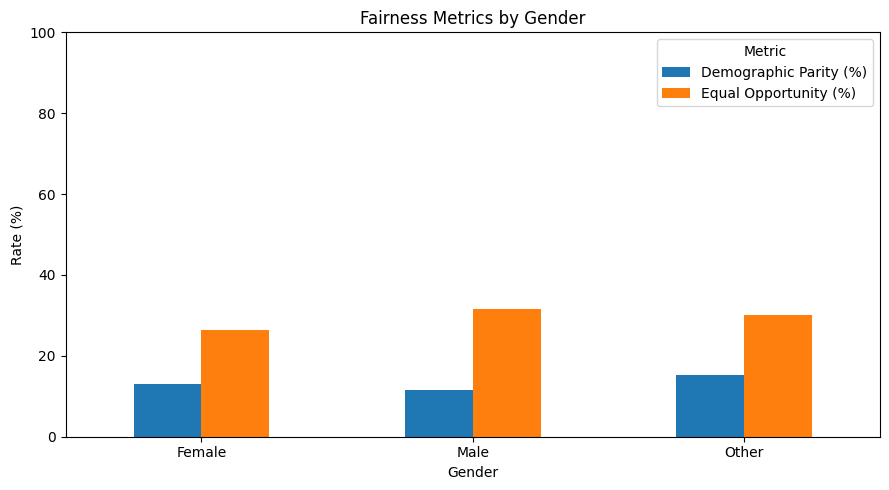

In [20]:

# Cell 13: Visualize fairness metrics

import matplotlib.pyplot as plt

plot_df = pd.DataFrame({
    "Demographic Parity (%)": (
        gender_results["positive_prediction_rate"] * 100
    ),
    "Equal Opportunity (%)": (
        eo_results["true_positive_rate"] * 100
    )
})

# Remove the Missing group from the gender comparison
plot_df = plot_df.drop(index="Missing", errors="ignore")

ax = plot_df.plot(kind="bar", figsize=(9, 5))

ax.set_title("Fairness Metrics by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Rate (%)")
ax.set_ylim(0, 100)
ax.legend(title="Metric")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
